<a href="https://colab.research.google.com/github/bmulaw/ComputerVision/blob/main/ComputerVision_lab1_pixelsToFoundationModels.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Team Name/Member: Bernard MULAW
#### Date: 30/10/2026

In [1]:
import platform
print(platform.python_version())
# print("hello world")

3.13.16


In [2]:
%pip -q install "opencv-python" " git+https://github.com/openai/CLIP.git" "segment-anything"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
# https://pypi.org/project/segment-anything-py/, https://github.com/openai/CLIP
import clip
import torch
from PIL import Image
from segment_anything import SamPredictor, sam_model_registry, SamAutomaticMaskGenerator
import numpy as np
import cv2
import os
from matplotlib import pyplot as plt
from matplotlib import image as mpimg
from google.colab import drive, files

In [4]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
print(torch.__version__)
torch.cuda.is_available()

2.14.1+cu130


True

In [6]:
device = "cpu"
model, preprocess = clip.load("ViT-B/32", device=device)

100%|████████████████████████████████████████| 338M/338M [00:01<00:00, 307MiB/s]
/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


In [7]:
class_names = ["cat", "dog", "bird", "horse"]
text = clip.tokenize([f"a photo of a {c}" for c in class_names]).to(device)

In [8]:
test_dir = "/content/drive/MyDrive/Colab " + "Notebooks/computer_vision/task1_dataset/test"

def run_clip_per_class(dir, tokneize_text):
  correct = 0
  total = 0

  per_class_accuracy = []

  for cls in class_names:
    cls_dir = os.path.join(test_dir, cls)
    new_class_accuracy_count = 0
    for img_name in sorted(os.listdir(cls_dir)):
      if not img_name.endswith(".jpg"):
        continue
      img_path = os.path.join(cls_dir, img_name)
      # clip's preprocessing (note to self: look up unsqueeze?)
      image = preprocess(Image.open(img_path)).unsqueeze(0).to(device)

      with torch.no_grad():
        logits, _ = model(image, text)
        probs = logits.softmax(dim=-1)[0]
      pred = class_names[probs.argmax()]
      correct += (pred == cls)
      total += 1
      new_class_accuracy_count += (pred == cls)
    per_class_accuracy += [{cls: new_class_accuracy_count/25}]

  print(f"Accuracy: {correct}/{total} = {correct/total * 100:.1f}%")
  print(per_class_accuracy)

# run_clip_per_class(test_dir, text)

## Task 2.1: Zero-Shot Classification

In [9]:
test_dir_10random = "/content/drive/MyDrive/Colab " + "Notebooks/computer_vision/task1_dataset/test/random10"

# TODO : Load CLIP model (ViT -B /32) --> DONE
# TODO : Define class names --> DONE
# TODO : Load all images from folder --> DONE
# TODO : For each image :
# - Preprocess image  --> DONE
# - Tokenize text --> DONE
# - Compute similarity --> DONE
# - Output : image_name -> predicted_class ( confidence ) --> DONE
def run_clip(test_dir, tokenized_text):
  correct_pred = 0
  total_predicted = 0
  for img_name in sorted(os.listdir(test_dir)):
    if not img_name.endswith(".jpg"):
      continue
    img_path = test_dir + "/" + img_name
    image = preprocess(Image.open(img_path)).unsqueeze(0).to(device)

    with torch.no_grad():
      logits, _ = model(image, tokenized_text)
      probs = logits.softmax(dim=-1)[0]

    pred = class_names[probs.argmax()]
    confidence = round(float(max(probs)), 3)
    actual = img_name.split('_')[1]
    correct_pred += (pred == actual)
    total_predicted += 1
    print("image_class =", actual, 'model pred =', pred, "with confidence of", confidence)


  print(f"Accuracy: {correct_pred}/{total_predicted} = {correct_pred/total_predicted *100:.1f}%")

# run_clip(test_dir_10random, text)


## Task 2.2 Prompt Engineering

In [10]:
prompt1 = clip.tokenize([f"a {c}" for c in class_names]).to(device)
prompt2 = clip.tokenize([f"a photo of a {c}" for c in class_names]).to(device)
prompt3_list = ["felis catus", "canis familiaris", "aves", "equus ferus caballus"]
prompt3 = clip.tokenize([p for p in prompt3_list]).to(device)

In [11]:
# print("----------- PROMPT 1 ----------- ")
# run_clip(test_dir_10random, prompt1)
# print("----------- PROMPT 2 ----------- ")
# run_clip(test_dir_10random, prompt2)
# print("----------- PROMPT 3 ----------- ")
# run_clip(test_dir_10random, prompt3)

## Task 2.3: Image Retrieval

*Build an image retrieval system. Given a query image, find the most similar images from a collection using CLIP embeddings.*

In [12]:
def get_top_n_scores(scores, n=3):
  # yes i know this is God-awful code but its written purely by my hand :)
  res = scores[:n]
  min_so_far = min( [s[1][0] for s in res] )
  for score in scores[n:]:
    if score[1][0] > min_so_far:
      for i, s in enumerate(res):
        if s[1] == min_so_far:
          res[i] = score
          min_so_far = min( [s[1][0] for s in res] )
          break
  return res

# [(a, 2), (b, 5), (c,6)]
# (a, 2), (b, 5), (c,6), (d, 10), (e, 1), (f, 0), (g, 11), (h, 8)

# min: 2
# loop:
  # l1, s = d,10
    # min: 2
    # loop:
      # 0, (a,2)
      # matches --> res[((d, 10), (b, 5), (c,6))]
      # min: 5
  # l2, s = e,1
    # no loop
  # l3, s = f,0
    # no loop
  # l4, s = g,11
    # min: 5
    # loop:
      # 0, (d,10)
      # 1, (b,5)
      # matches --> res[((d, 10), (g,11), (c,6))]
    # ...

In [13]:
# TODO: Load CLIP model --> DONE
# TODO: Load query + candidate images --> DONE

# TODO: Compute embeddings for all images --> DONE
# Hint: model.encode_image()

# TODO: Compute cosine similarity --> DONE
# Similarity = embedding1 @ embedding2.T

# TODO: Rank candidates by similarity --> DONE
# Output: top -3 most similar images

# TODO: Visualize: Query image side-by-side with top-3 retrieved images

def retrieve_image_by_query(query,
                            image_directory="/content/drive/MyDrive/Colab " + "Notebooks/computer_vision/task1_dataset/test"):
  print("Looking for images that is:", query)

  # found code here: https://github.com/openai/CLIP
  scores_for_images = [] # list of sets, the image and the similarity score
  tokenized_text = clip.tokenize(query).to(device)
  for cls in class_names:
    cls_dir = os.path.join(image_directory, cls)
    for img_name in sorted(os.listdir(cls_dir)):
      if not img_name.endswith(".jpg"):
        continue
      img_path = cls_dir + "/" + img_name
      image = preprocess(Image.open(img_path)).unsqueeze(0).to(device)


      with torch.no_grad():
        encoded_img = model.encode_image(image)
        encoded_text = model.encode_text(tokenized_text)

      encoded_img /= encoded_img.norm(dim=-1, keepdim=True)
      encoded_text /= encoded_text.norm(dim=-1, keepdim=True)
      similarity = encoded_text.cpu().numpy() @ encoded_img.cpu().numpy().T

      scores_for_images.append((img_path, similarity[0]))
    print("finished on " + cls + " images")

  top_3_images = get_top_n_scores(scores_for_images)
  # found code here: https://www.askpython.com/python/examples/display-images-using-python
  for img, score in top_3_images:
    s = str(round(score[0], 3)*100) + "%"
    plt.title("Image ranked with score " + s)
    image = mpimg.imread(img)
    plt.imshow(image)
    plt.show()


query = "guys just being guys"
# retrieve_image_by_query(query)

In [14]:
# this is fun, i wanted to try a differnt prompt lol
query = "what screams money"
# retrieve_image_by_query(query)

In [15]:
# this is fun, i wanted to try a differnt prompt lol
query = "going on an adventure"
# retrieve_image_by_query(query)

# Part 3: SAM - Interactive Segmentation

## Task 3.1: Batch Segmentation

*Segment all images in a folder using SAM's “automatic mask generation” mode. Save each mask as a PNG file.*

In [16]:
%cd /content/drive/MyDrive/Colab\ Notebooks/computer_vision/task1_dataset
%mkdir segmask_img

/content/drive/MyDrive/Colab Notebooks/computer_vision/task1_dataset
mkdir: cannot create directory ‘segmask_img’: File exists


In [19]:
# TODO: Load SAM model
sam = sam_model_registry["vit_h"](checkpoint="sam_vit_h_4b8939.pth")
sam.to(device="cuda")
mask_generator = SamAutomaticMaskGenerator(sam)

In [24]:
def show_and_return_anns(anns):
    if len(anns) == 0:
        return
    sorted_anns = sorted(anns, key=(lambda x: x['area']), reverse=True)
    ax = plt.gca()
    ax.set_autoscale_on(False)

    img = np.ones((sorted_anns[0]['segmentation'].shape[0], sorted_anns[0]['segmentation'].shape[1], 4))
    img[:,:,3] = 0
    for ann in sorted_anns:
        m = ann['segmentation']
        color_mask = np.concatenate([np.random.random(3), [0.35]])
        img[m] = color_mask
    ax.imshow(img)
    return img

img_name: test_bird_0002.jpg


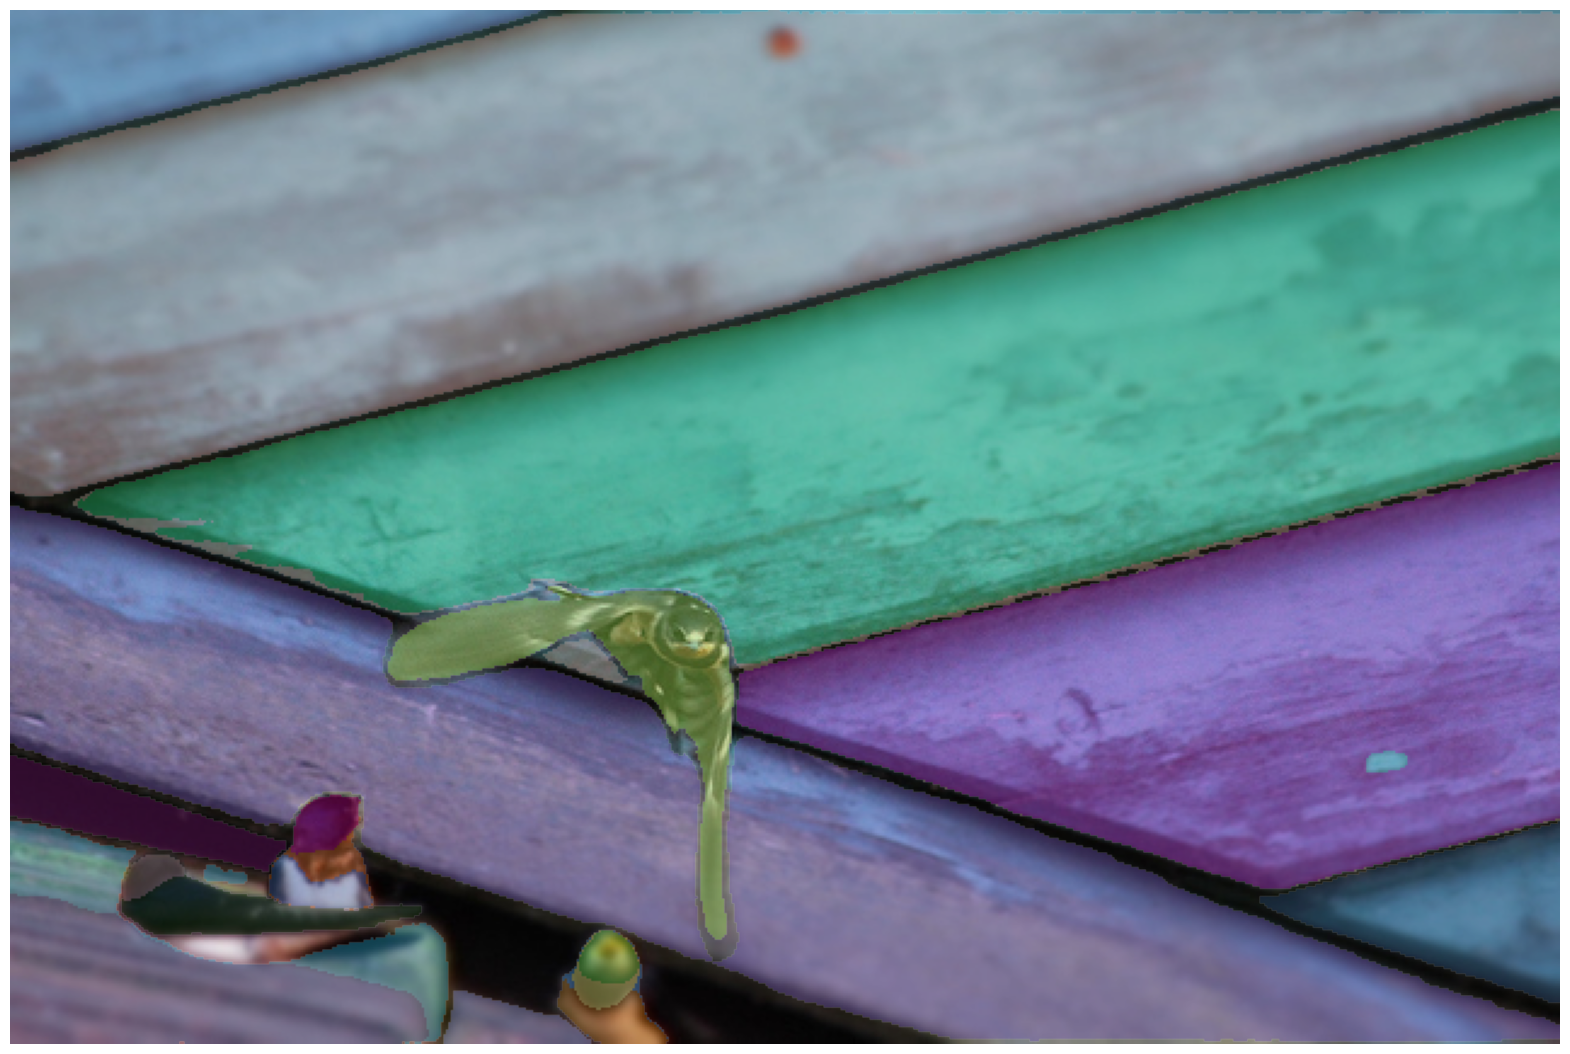

img_name: test_bird_0011.jpg


In [ ]:
# TODO: Loop through all images in folder
def generate_and_save_segmasks(
    image_directory="/content/drive/MyDrive/Colab " + "Notebooks/computer_vision/task1_dataset/test/random10"):

  for img_name in sorted(os.listdir(image_directory)):
    if not img_name.endswith(".jpg"):
      continue
    print("img_name:", img_name)
    img_path = os.path.join(image_directory, img_name)
    # image = preprocess(Image.open(img_path)).unsqueeze(0).to(device)
    image = mpimg.imread(img_path)
    # TODO: Generate masks for each image
    masks = mask_generator.generate(image)
    # plt.figure(figsize=(20,20))

    # plt.imshow(image)
    masked_img = show_and_return_anns(masks)
    plt.axis('off')
    plt.show()


    # TODO: Save each mask as PNG
    # Point prompt
    # predictor = SamPredictor(sam)
    # predictor.set_image(image)
    # input_point = np.array([[image, masks]])
    # input_label = np.array([1])
    # masks, scores, logits = predictor.predict(
    #   point_coords = input_point,
    #   point_labels = input_label,
    #   multimask_output = True,
    # )
    # plt.imshow(image)
    # plt.savefig(image)

    # mask_predictor = SamPredictor(sam)
    # mask_predictor.set_image(image_rgb)
    # # Predict mask with bounding box prompt
    # masks, scores, logits = mask_predictor.predict(
    # box=bbox_prompt,
    # multimask_output=False
    # )
    # # Plot the bounding box prompt and predicted mask
    # plt.imshow(image_rgb)
    # show_mask(masks[0], plt.gca())
    # show_box(bbox_prompt, plt.gca())
    # plt.show()

generate_and_save_segmasks()



## Task 3.2: Interactive Segmentation with Point Prompt

*Given a point coordinate (x, y), use SAM to generate the mask for the object at that point.*

In [ ]:
# TODO: Load SAM model
# TODO: Load image

# TODO: Define point prompt
# input_point = np.array([[x, y]])
# input_label = np.array([1]) # 1 = foreground

# TODO: Predict mask
# mask, score, _ = predictor.predict(...)

# TODO: Visualize: image with point, mask overlay, and confidence score

# Part 4: CLIP + SAM Integration

*Build a system that takes a complext image and a text query (e.g., "the dog wearing a red collar") and gives outputs of a segmentation mask for the object described in the query and a visualization showing the mask overlaid on the image.*

- No manual annotations
- No hard-coded coordinates
- Maximum 50 lines of code
- Use CLIP + SAM only

In [ ]:
# TODO: Load CLIP

# TODO: Load SAM

# TODO: Load image and query

# TODO: Generate candidate masks

# TODO: Rank masks with CLIP

# TODO: Select best mask and visualize

In [ ]:
def clip():
  device = "cuda" if torch.cuda.is_available() else "cpu"
  model, preprocess = clip.load("ViT -B/32", device=device)

  # Preprocess image
  image = preprocess(Image.open("image.jpg")).unsqueeze(0).to(device)

  # Tokenize text
  text = clip.tokenize(["a cat", "a dog", "a bird", "a horse"]).to(device)

  # Compute similarity
  with torch.no_grad():
    logits_per_image, logits_per_text = model(image, text)
    probs = logits_per_image.softmax(dim = -1).cpu().numpy()

  # Get embedding
  with torch.no_grad():
    image_features = model.encode_image(image)
    text_features = model.encode_text(text)

In [ ]:
def sam(image, x, y):
  sam = sam_model_registry ["vit_h"](checkpoint="sam_vit_h_4b8939.pth")
  sam.to(device="cuda")

  # Automatic mask generation
  mask_generator = SamAutomaticMaskGenerator(sam)
  masks = mask_generator.generate(image)

  # Point prompt
  predictor = SamPredictor(sam)
  predictor.set_image(image)
  input_point = np.array([[x, y]])
  input_label = np.array([1])
  masks, scores, logits = predictor.predict(
    point_coords = input_point,
    point_labels = input_label,
    multimask_output = True,
  )